**compute the ratio for every pair**

In [1]:
%load_ext autoreload
%autoreload 2

import pandas as pd

from fxml import config
from fxml.db.connection import connect
from fxml.db.repository import load_bars
from fxml.evaluation import plots
from fxml.evaluation.backtest import spread_cost
from fxml.features import indicators as ind

plots.apply_style()
conn = connect()

rows = []
for symbol in config.SYMBOLS:
    bars = load_bars(conn, symbol, "H1", start=config.TRAIN_START)
    atr_bps = ind.atr(bars["high"], bars["low"], bars["close"], 14) / bars["close"] * 1e4
    cost_bps = spread_cost(bars, config.POINT_SIZES[symbol]) * 1e4
    rows.append({"symbol": symbol, "bars": len(bars),
                 "cost_bps": cost_bps.median(), "atr_bps": atr_bps.median(),
                 "cost_to_atr": cost_bps.median() / atr_bps.median()})

screen = pd.DataFrame(rows).set_index("symbol").sort_values("cost_to_atr")
limit = 1.5 * screen.loc["EURUSD", "cost_to_atr"]
screen["keep"] = screen["cost_to_atr"] <= limit
screen.round(3)


,bars,cost_bps,atr_bps,cost_to_atr,keep
symbol,,,,,
EURUSD,73387,0.636,12.041,0.053,True
GBPUSD,73403,0.760,13.657,0.056,True
EURJPY,73398,0.854,14.107,0.061,True
GBPJPY,73313,1.053,16.363,0.064,True
USDJPY,73316,0.919,13.175,0.070,True
USDCAD,73399,0.867,11.404,0.076,True
AUDUSD,73399,1.423,16.862,0.084,False
USDCHF,73373,1.092,12.654,0.086,False
AUDJPY,73394,1.746,18.450,0.095,False


**The Chart**

kept: ['EURUSD', 'GBPUSD', 'EURJPY', 'GBPJPY', 'USDJPY', 'USDCAD']
dropped: ['AUDUSD', 'USDCHF', 'AUDJPY', 'NZDUSD', 'EURGBP']


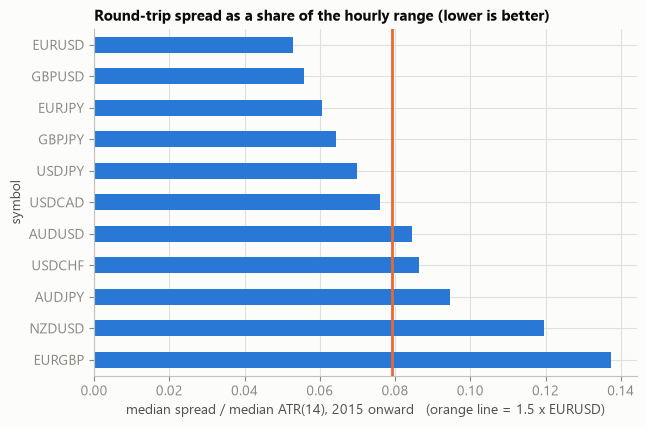

In [2]:
ax = screen["cost_to_atr"].iloc[::-1].plot.barh(
    color=plots.BLUE, figsize=(7, 4.5),
    title="Round-trip spread as a share of the hourly range (lower is better)")
ax.axvline(limit, color=plots.ORANGE, linewidth=2)
ax.set_xlabel("median spread / median ATR(14), 2015 onward   (orange line = 1.5 x EURUSD)")
print("kept:", list(screen.index[screen["keep"]]))
print("dropped:", list(screen.index[~screen["keep"]]))
